# Density-based outlier detection: one density threshold for the whole dataset
**Data Centric AI – Outlier detection** · Master Degree in Computer Science

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matteogolfarelli/DataCentricAI/blob/main/Outlier%20Detection/Density_outlier_detection.ipynb)

This notebook shows the **density-based approach** at work (slides *Density-based Approaches*):

* an outlier is a point located in an area of **very low density**;
* density is computed either as the inverse of the average distance to the k nearest neighbors, or with the DBSCAN notion of density (number of points within a radius ε).

On a dataset with **clusters of different density** a single (absolute) density threshold cannot work: we will measure how much worse it performs than the **relative density** used by LOF.

Same dataset as the kNN, LOF and Isolation Forest notebooks. Runs on CPU in a few seconds.

## 1. The dataset
Dense cluster **A** (300 points), sparse cluster **B** (200), small normal cluster **C** (10); outliers: 4 **global**, a **group** of 5, 4 **local** outliers close to A. Labels are used only for the evaluation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.metrics import roc_auc_score
import pandas as pd

def make_dataset(seed=0):
    """2-D dataset shared by the kNN, density, LOF and iForest examples."""
    rng = np.random.default_rng(seed)
    A = rng.normal([0, 0], 0.2, (300, 2))          # dense cluster
    B = rng.normal([6, 0], 1.2, (200, 2))          # sparse cluster
    C = rng.normal([2.5, 5.0], 0.15, (10, 2))      # small, but NORMAL, cluster
    glob = np.array([[-4., -4.], [3., -5.], [11., 5.], [10., -5.]])   # global outliers
    grp  = rng.normal([-3.5, 3.0], 0.08, (5, 2))   # group of outliers (micro-cluster)
    ang  = np.array([0.3, 1.9, 3.4, 4.9])
    loc  = np.c_[1.3*np.cos(ang), 1.3*np.sin(ang)] # local outliers close to A
    X = np.vstack([A, B, C, glob, grp, loc])
    kind = np.array(['A']*300 + ['B']*200 + ['C']*10 + ['global']*4 + ['group']*5 + ['local']*4)
    y = np.isin(kind, ['global', 'group', 'local']).astype(int)   # 1 = outlier (used ONLY to evaluate)
    return X, y, kind

X, y, kind = make_dataset()
N_OUT = int(y.sum())                 # 13 outliers out of 523 points
TYPES = ['global', 'group', 'local', 'A', 'B', 'C']
print(X.shape, '-', N_OUT, 'outliers')
pd.Series(kind).value_counts().reindex(TYPES).to_frame('points').T

(523, 2) - 13 outliers


,global,group,local,A,B,C
points,4,5,4,300,200,10


In [2]:
NORM_C, OUT_C, FP_C = '#4C78A8', '#C0392B', '#E67E22'

def top_n(score, n=N_OUT):
    """Unsupervised labelling: the n points with the highest anomaly score are outliers."""
    flag = np.zeros(len(score), bool)
    flag[np.argsort(-score)[:n]] = True
    return flag

def evaluate(score, name='', n=N_OUT):
    """Ground truth is used only here, to assess the result."""
    f = top_n(score, n)
    row = {'ROC AUC': round(roc_auc_score(y, score), 3), 'P@n': round(y[f].mean(), 2)}
    row.update({f'{t} flagged': int(f[kind == t].sum()) for t in TYPES})
    return pd.DataFrame(row, index=[name])

def detect_plot(ax, score, title='', n=N_OUT):
    f = top_n(score, n)
    tp, fp, fn = f & (y == 1), f & (y == 0), ~f & (y == 1)
    ax.scatter(*X[(y == 0) & ~fp].T, s=12, c=NORM_C, alpha=.45, lw=0, label='normal')
    ax.scatter(*X[tp].T, s=55, marker='x', c=OUT_C, lw=1.8, label=f'detected outliers TP ({tp.sum()})')
    ax.scatter(*X[fn].T, s=90, facecolors='none', edgecolors='k', lw=1.4, label=f'missed outliers FN ({fn.sum()})')
    ax.scatter(*X[fp].T, s=60, c=FP_C, edgecolors='k', lw=.5, label=f'false alarms FP ({fp.sum()})')
    ax.set_title(title); ax.set_aspect('equal')
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

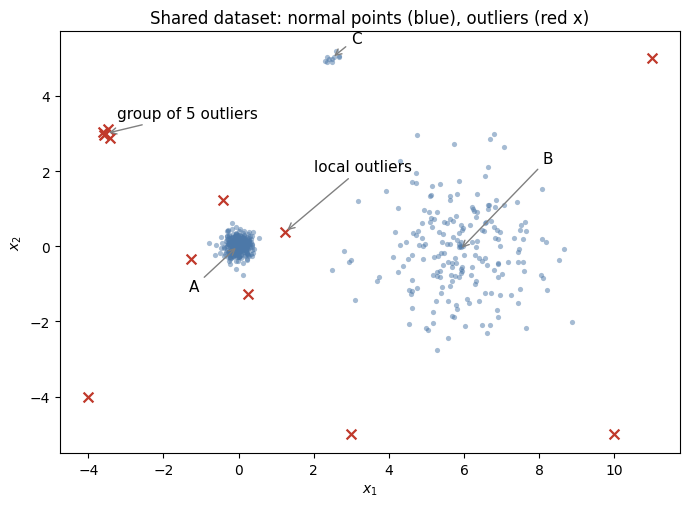

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
style = {'A': (NORM_C, 'o'), 'B': (NORM_C, 'o'), 'C': (NORM_C, 'o'),
         'global': (OUT_C, 'x'), 'group': (OUT_C, 'x'), 'local': (OUT_C, 'x')}
for t, (c, m) in style.items():
    ax.scatter(*X[kind == t].T, s=14 if m == 'o' else 50, c=c, marker=m, alpha=.5 if m == 'o' else 1, lw=1.6 if m == 'x' else 0)
for t, (dx, dy) in {'A': (-1.3, -1.2), 'B': (2.2, 2.3), 'C': (0.5, 0.4), 'group': (0.3, 0.4)}.items():
    cx, cy = X[kind == t].mean(axis=0)
    ax.annotate(t if t != 'group' else 'group of 5 outliers', (cx, cy), (cx + dx, cy + dy), fontsize=11,
                arrowprops=dict(arrowstyle='->', color='gray'))
ax.annotate('local outliers', (1.24, 0.38), (2.0, 2.0), fontsize=11, arrowprops=dict(arrowstyle='->', color='gray'))
ax.set_title('Shared dataset: normal points (blue), outliers (red x)'); ax.set_aspect('equal')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); plt.show()

## 2. Density as inverse of the average distance
$$density(x,k)=\left(\frac{\sum_{y\in N(x,k)} dist(x,y)}{|N(x,k)|}\right)^{-1}$$
The anomaly score is the inverse of the density. Note that, by construction, this density gives **exactly the same ranking** as the kNN distance score: density-based and distance-based approaches are two sides of the same coin.

Spearman correlation between density and kNN distance score: -0.9999999999999998


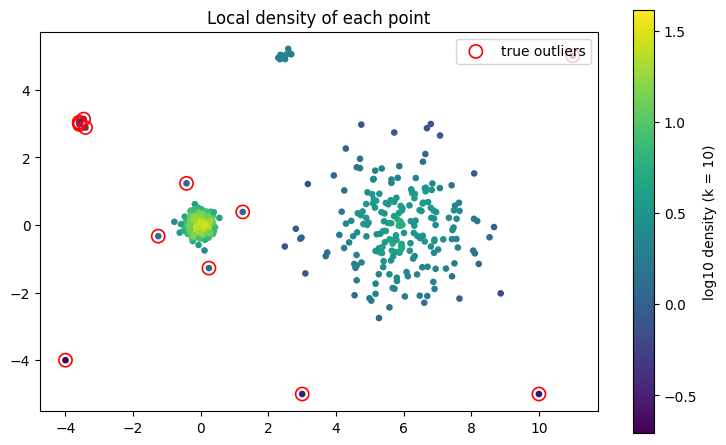

,global,group,local,A,B,C
median density,0.22,0.41,1.16,19.23,2.62,2.03
min,0.20,0.40,1.11,2.50,0.64,1.80
max,0.28,0.42,1.22,41.53,6.13,2.28


In [4]:
K = 10
dist, idx = NearestNeighbors(n_neighbors=K + 1).fit(X).kneighbors(X)
avg_dist = dist[:, 1:].mean(axis=1)
density = 1 / avg_dist

from scipy.stats import spearmanr
print('Spearman correlation between density and kNN distance score:', spearmanr(density, avg_dist)[0])

fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(*X.T, c=np.log10(density), cmap='viridis', s=14)
ax.scatter(*X[y == 1].T, s=90, facecolors='none', edgecolors='r', lw=1.2, label='true outliers')
plt.colorbar(sc, label='log10 density (k = 10)'); ax.legend(loc='upper right'); ax.set_aspect('equal')
ax.set_title('Local density of each point'); plt.show()

pd.DataFrame({t: [np.median(density[kind == t]), density[kind == t].min(), density[kind == t].max()] for t in TYPES},
             index=['median density', 'min', 'max']).round(2)

The **local outliers** have a density (≈ 1.1–1.2) about **16 times lower than the points of A** around them (≈ 19), but **higher than many points of the sparse cluster B**: in absolute terms they are not in a low-density area.

## 3. One threshold for the whole dataset
We label as outliers the top-n (n = 13) points with the lowest density, then we look at the full trade-off: lowering the threshold, how many normal points must be flagged to catch the local outliers?

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
density k=10,0.989,0.69,4,5,0,0,4,0


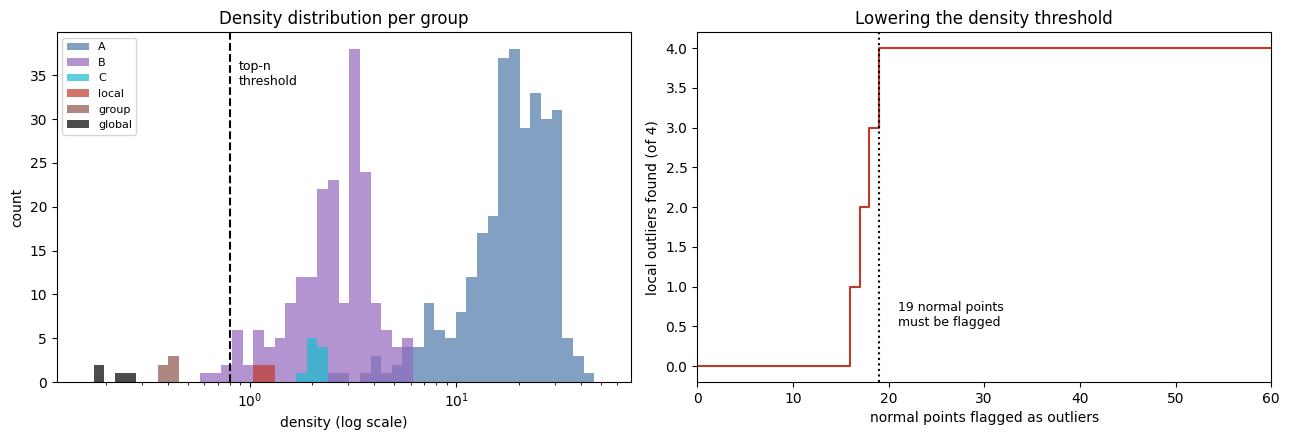

To catch all 4 local outliers we must also flag 19 normal points (all from the sparse cluster B): precision <= 0.41


In [5]:
score_density = -density
display(evaluate(score_density, 'density k=10'))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.logspace(np.log10(density.min()) - .1, np.log10(density.max()) + .1, 50)
for t, c in [('A', NORM_C), ('B', 'tab:purple'), ('C', 'tab:cyan'), ('local', OUT_C), ('group', 'tab:brown'), ('global', 'k')]:
    ax1.hist(density[kind == t], bins=bins, color=c, alpha=.7, label=t)
thr = np.sort(density)[N_OUT - 1]
ax1.axvline(thr, ls='--', c='k'); ax1.text(thr * 1.1, 0.85, 'top-n\nthreshold', fontsize=9, transform=ax1.get_xaxis_transform())
ax1.set_xscale('log'); ax1.set_xlabel('density (log scale)'); ax1.set_ylabel('count'); ax1.legend(fontsize=8)

# threshold sweep: points sorted by increasing density
order = np.argsort(density)
found_local = np.cumsum(kind[order] == 'local')
flagged_normal = np.cumsum(y[order] == 0)
ax2.plot(flagged_normal, found_local, c=OUT_C)
ax2.set_xlabel('normal points flagged as outliers'); ax2.set_ylabel('local outliers found (of 4)')
need = flagged_normal[np.argmax(found_local == 4)]
ax2.axvline(need, ls=':', c='k'); ax2.text(need + 2, 0.5, f'{need} normal points\nmust be flagged', fontsize=9)
ax2.set_xlim(0, 60); ax1.set_title('Density distribution per group'); ax2.set_title('Lowering the density threshold')
plt.tight_layout(); plt.show()
print(f'To catch all 4 local outliers we must also flag {need} normal points (all from the sparse cluster B):',
      f'precision <= {13 / (13 + need):.2f}')

## 4. The DBSCAN notion of density
A point is *core* if it has at least `min_samples` points within radius ε; points that are neither core nor reachable from a core point are **noise** = outliers. Again, ε is **one radius for the whole dataset**.

In [6]:
from sklearn.cluster import DBSCAN
rows = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2]:
    noise = DBSCAN(eps=eps, min_samples=10).fit(X).labels_ == -1
    rows.append({'eps': eps, **{f'{t} as noise': int(noise[kind == t].sum()) for t in TYPES}})
pd.DataFrame(rows).set_index('eps')

,global as noise,group as noise,local as noise,A as noise,B as noise,C as noise
eps,,,,,,
0.3,4,5,4,1,168,0
0.4,4,5,4,0,104,0
0.5,4,5,4,0,64,0
0.6,4,5,3,0,35,0
0.8,4,5,0,0,12,0
1.0,4,5,0,0,7,0
1.2,4,5,0,0,1,0


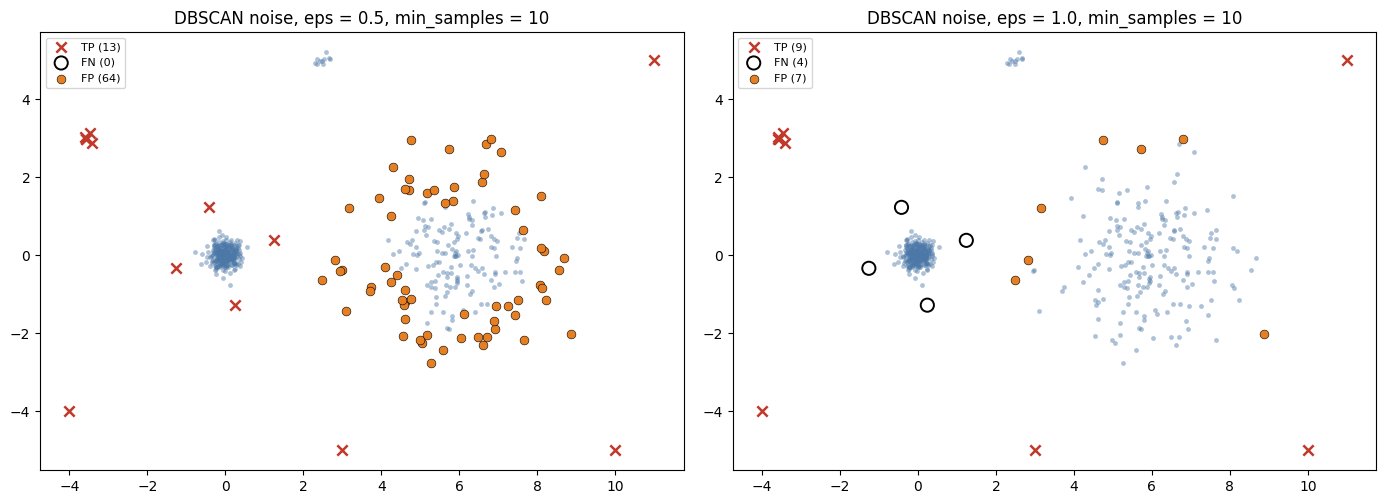

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, eps in zip(axes, [0.5, 1.0]):
    noise = DBSCAN(eps=eps, min_samples=10).fit(X).labels_ == -1
    tp, fp, fn = noise & (y == 1), noise & (y == 0), ~noise & (y == 1)
    ax.scatter(*X[~noise & (y == 0)].T, s=12, c=NORM_C, alpha=.45, lw=0)
    ax.scatter(*X[tp].T, s=55, marker='x', c=OUT_C, lw=1.8, label=f'TP ({tp.sum()})')
    ax.scatter(*X[fn].T, s=90, facecolors='none', edgecolors='k', lw=1.4, label=f'FN ({fn.sum()})')
    ax.scatter(*X[fp].T, s=40, c=FP_C, edgecolors='k', lw=.4, label=f'FP ({fp.sum()})')
    ax.set_title(f'DBSCAN noise, eps = {eps}, min_samples = 10'); ax.set_aspect('equal'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

* ε ≤ 0.5: the local outliers are noise, but so are **64 or more points of B** (swamping);
* ε ≥ 0.8: B is a cluster again, but the local outliers are **absorbed** (masking).

No value of ε works for both clusters.

## 5. Relative density: LOF
LOF compares the density of a point with the **density of its neighbors**:
$$LOF(x,k)=\frac{1}{|N(x,k)|}\sum_{y\in N(x,k)}\frac{lrd(y,k)}{lrd(x,k)}$$
A local outlier has a density much lower than that of its neighbors (points of A) → LOF ≫ 1; a point of B has a low density, but **similar to that of its neighbors** → LOF ≈ 1.

In [8]:
lof = -LocalOutlierFactor(n_neighbors=K).fit(X).negative_outlier_factor_
pd.concat([evaluate(avg_dist, 'kNN distance k=10'), evaluate(score_density, 'density k=10'), evaluate(lof, 'LOF k=10')])

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
kNN distance k=10,0.989,0.69,4,5,0,0,4,0
density k=10,0.989,0.69,4,5,0,0,4,0
LOF k=10,1.000,1.00,4,5,4,0,0,0


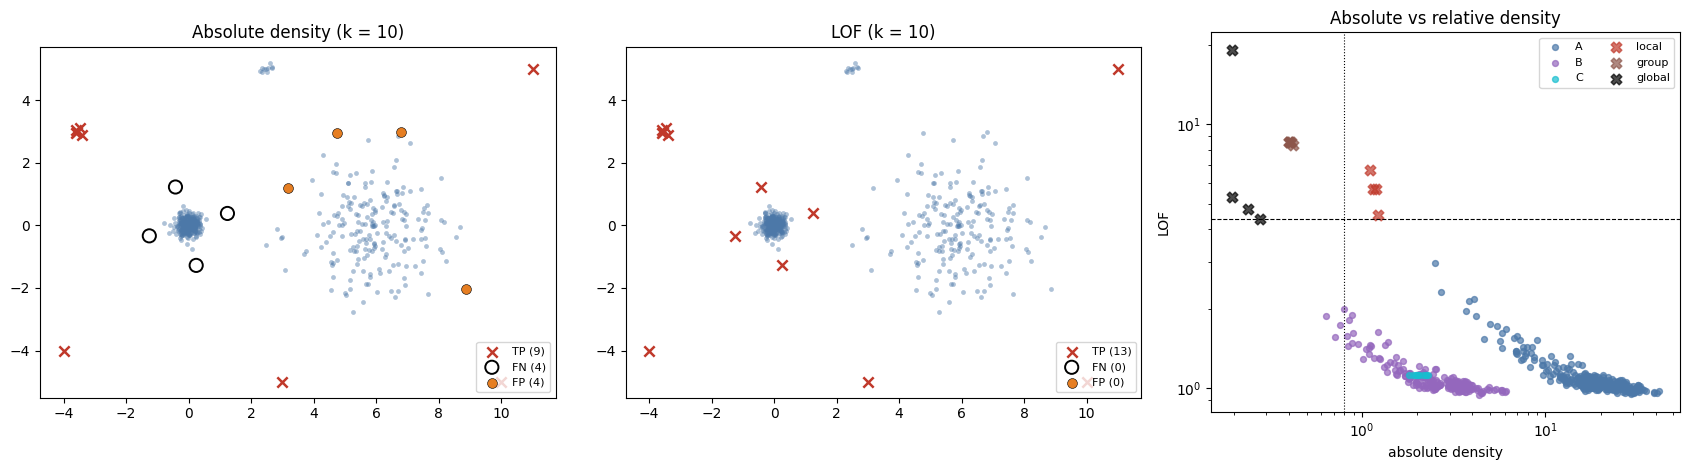

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={'width_ratios': [1.1, 1.1, 1]})
for ax, s, t in [(axes[0], score_density, 'Absolute density (k = 10)'), (axes[1], lof, 'LOF (k = 10)')]:
    f = top_n(s); tp, fp, fn = f & (y == 1), f & (y == 0), ~f & (y == 1)
    ax.scatter(*X[~f & (y == 0)].T, s=12, c=NORM_C, alpha=.45, lw=0)
    ax.scatter(*X[tp].T, s=55, marker='x', c=OUT_C, lw=1.8, label=f'TP ({tp.sum()})')
    ax.scatter(*X[fn].T, s=90, facecolors='none', edgecolors='k', lw=1.4, label=f'FN ({fn.sum()})')
    ax.scatter(*X[fp].T, s=50, c=FP_C, edgecolors='k', lw=.4, label=f'FP ({fp.sum()})')
    ax.set_title(t); ax.set_aspect('equal'); ax.legend(fontsize=8, loc='lower right')
ax = axes[2]
for t, c, m in [('A', NORM_C, 'o'), ('B', 'tab:purple', 'o'), ('C', 'tab:cyan', 'o'), ('local', OUT_C, 'X'), ('group', 'tab:brown', 'X'), ('global', 'k', 'X')]:
    ax.scatter(density[kind == t], lof[kind == t], s=18 if m == 'o' else 60, c=c, marker=m, alpha=.7, label=t)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('absolute density'); ax.set_ylabel('LOF')
ax.axhline(np.sort(lof)[-N_OUT], ls='--', c='k', lw=.8); ax.axvline(np.sort(density)[N_OUT - 1], ls=':', c='k', lw=.8)
ax.legend(fontsize=8, ncol=2); ax.set_title('Absolute vs relative density')
plt.tight_layout(); plt.show()

In the right plot the dotted line is the top-n threshold on the absolute density (points on its left are flagged) and the dashed line the top-n threshold on LOF (points above it are flagged). The local outliers lie *on the right* of the dotted line (not detected by density) but well *above* the dashed line (detected by LOF), while the points of B have low density but LOF ≈ 1.

## Takeaways
**Pros of the (absolute) density-based approach**
* Intuitive definition; no assumption on the data distribution; works well for global outliers.
* The DBSCAN variant gives outliers "for free" while clustering the data.

**Cons**
* Same limits as the distance-based approach (it produces the same ranking): sensitive to k, O(N²).
* **One density threshold for the whole dataset**: with clusters of different density it either misses the local outliers (masking) or flags the sparse clusters (swamping).
* On this dataset: P@n = 0.69 vs **1.00 for LOF**; catching all the local outliers costs ≥ 19 false alarms.

**Try yourself**: make B as dense as A (σ = 0.2): the absolute density now works. What happens to the gap with LOF?